# SMS Spam Detection : BiLSTM vs TF-IDF

**Author:** Fils Aboubakar Sidik MBOHOU  
**School:** ESAIP Engineering School, France  
**Program:** MSc Cybersecurity & Data Science  
**Program period:** 2024–2026  
**Project type:** Individual academic project

This notebook classifies SMS messages as **ham** or **spam** and compares two approaches: a Bidirectional LSTM and TF-IDF + Logistic Regression.

The project uses the 5,572-row CSV variant of the SMS Spam Collection. After removing exact duplicate messages, 5,157 unique messages remain for modeling. The main question is not only which model scores best, but whether the extra complexity of the BiLSTM produces a meaningful gain over a much simpler baseline.


## 1. Environment and reproducibility

A fixed random seed is used for reproducibility. The published outputs were generated with the **JAX** Keras backend. To make the public notebook easier to run on Windows, the setup cell uses JAX when it is installed and otherwise falls back to TensorFlow, then PyTorch.

> Deep-learning scores can vary slightly with the backend, operating system and library versions. The data split, threshold-selection rule and evaluation protocol stay unchanged.

Required packages: `numpy`, `pandas`, `matplotlib`, `scikit-learn`, `keras` and at least one Keras backend (`jax`, `tensorflow` or `torch`).


In [1]:
# Select an available Keras backend before importing Keras.
import importlib.util
import os
from pathlib import Path

os.environ["PYTHONHASHSEED"] = "42"
os.environ.setdefault("MPLCONFIGDIR", str((Path.cwd() / ".mplconfig").resolve()))

if "KERAS_BACKEND" not in os.environ:
    if importlib.util.find_spec("jax") is not None:
        os.environ["KERAS_BACKEND"] = "jax"
    elif importlib.util.find_spec("tensorflow") is not None:
        os.environ["KERAS_BACKEND"] = "tensorflow"
    elif importlib.util.find_spec("torch") is not None:
        os.environ["KERAS_BACKEND"] = "torch"
    else:
        raise ImportError(
            "Install a Keras backend first: tensorflow, jax or torch."
        )

import json
import random
import re
import platform
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

import keras
from keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

ASSET_DIR = Path("spam_final_assets")
ASSET_DIR.mkdir(exist_ok=True)

print("Python:", platform.python_version())
print("Keras:", keras.__version__)
print("Keras backend:", keras.backend.backend())


Python: 3.13.5
Keras: 3.13.2
Keras backend: jax
Random seed: 42


## 2. Load and check the dataset

Place `spam.csv` in the same folder as the notebook. The loader accepts the two common schemas for the 5,572-row CSV variant:

- `Category`, `Message`; or
- `v1`, `v2` (the common Kaggle export).

The notebook verifies the exact row and class counts used for the portfolio results before continuing. This prevents a different SMS collection from silently producing different metrics.

Dataset origin: SMS Spam Collection by Almeida & Hidalgo (UCI Machine Learning Repository, DOI: https://doi.org/10.24432/C5CC84). The public CSV variant used here is the common 5,572-row export.

In [2]:
DATA_PATH = Path("spam.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Place spam.csv in the same folder as this notebook before running it. "
        "Expected: the 5,572-row SMS Spam Collection CSV variant."
    )

raw = pd.read_csv(DATA_PATH, encoding="latin1")
raw = raw.loc[:, ~raw.columns.astype(str).str.startswith("Unnamed")]

if {"Category", "Message"}.issubset(raw.columns):
    source = raw[["Category", "Message"]].copy()
elif {"v1", "v2"}.issubset(raw.columns):
    source = raw[["v1", "v2"]].rename(
        columns={"v1": "Category", "v2": "Message"}
    )
else:
    raise ValueError(
        "Unsupported spam.csv schema. Expected Category/Message or v1/v2. "
        f"Found: {list(raw.columns)}"
    )

print("Raw shape:", source.shape)
print("Missing values:")
print(source.isna().sum())

if source.isna().any().any():
    raise ValueError("The canonical project dataset contains no missing label/message values.")

df_raw = source.copy()
df_raw["Category"] = df_raw["Category"].astype(str).str.strip().str.lower()
df_raw["Message"] = df_raw["Message"].astype(str).str.strip()

print()
print("Raw class distribution:")
print(df_raw["Category"].value_counts())

expected = {"rows": 5572, "ham": 4825, "spam": 747}
observed = {
    "rows": len(df_raw),
    "ham": int((df_raw["Category"] == "ham").sum()),
    "spam": int((df_raw["Category"] == "spam").sum()),
}
if observed != expected:
    raise ValueError(
        "This notebook reproduces the published portfolio metrics for the "
        f"5,572-row CSV variant {expected}, but this file contains {observed}. "
        "Use the same spam.csv variant to reproduce the published scores."
    )


Raw shape: (5572, 2)
Missing values:
Category    0
Message     0
dtype: int64

Raw class distribution:
Category
ham     4825
spam     747
Name: count, dtype: int64


## 3. Explore the data

Before choosing a model, I look at the data itself.

The main questions are:

- How imbalanced are ham and spam messages?
- Are spam messages typically longer?
- Which words appear frequently in each class?

These checks do not train the final models. They help explain the problem and guide later choices such as class weighting and evaluation metrics.


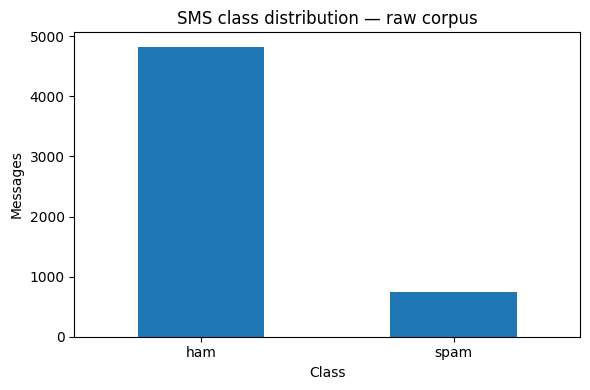

,count,mean,median,min,max
Category,,,,,
ham,4825,71.5,52.0,2,910
spam,747,138.4,149.0,7,224


In [3]:
# Message length is a simple descriptive feature for exploration only.
eda = df_raw.copy()
eda["message_length"] = eda["Message"].str.len()

# Class distribution
fig, ax = plt.subplots(figsize=(6, 4))
eda["Category"].value_counts().reindex(["ham", "spam"]).plot(kind="bar", ax=ax)
ax.set_title("SMS class distribution : raw corpus")
ax.set_xlabel("Class")
ax.set_ylabel("Messages")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(ASSET_DIR / "01_class_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

# Summary of message lengths by class
length_summary = eda.groupby("Category")["message_length"].agg(
    ["count", "mean", "median", "min", "max"]
)
display(length_summary.round(1))

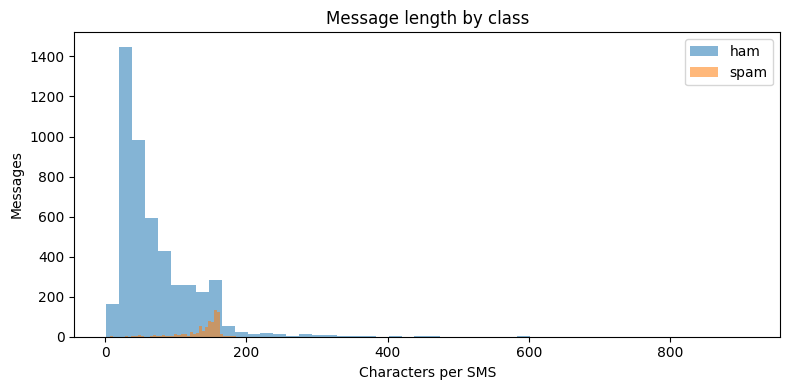

In [4]:
# Compare the distribution of SMS lengths for ham and spam.
fig, ax = plt.subplots(figsize=(8, 4))

for category in ["ham", "spam"]:
    lengths = eda.loc[eda["Category"] == category, "message_length"]
    ax.hist(lengths, bins=50, alpha=0.55, label=category)

ax.set_title("Message length by class")
ax.set_xlabel("Characters per SMS")
ax.set_ylabel("Messages")
ax.legend()
fig.tight_layout()
fig.savefig(ASSET_DIR / "02_message_length_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Remove exact duplicate messages

The dataset contains repeated SMS messages.

If the same message appears in both training and test data, the evaluation can become artificially easy because the model may see an identical example during training.

I therefore:

1. check that identical messages do not have contradictory labels;
2. remove exact duplicates;
3. split the remaining unique messages only after this cleanup.

This leaves **5,157 unique messages** for modeling.


In [5]:
# Number of distinct labels attached to each exact message.
label_counts_per_message = df_raw.groupby("Message")["Category"].nunique()
conflicting_messages = int((label_counts_per_message > 1).sum())

# Count repeated messages, keeping the first occurrence as the canonical row.
exact_duplicates = int(
    df_raw.duplicated(subset=["Message"], keep="first").sum()
)

print("Exact duplicate rows:", exact_duplicates)
print("Identical messages with conflicting labels:", conflicting_messages)

if conflicting_messages > 0:
    raise ValueError(
        "At least one identical message has different labels. Manual review is required."
    )

# Canonical modeling corpus: one row per exact message.
df = df_raw.drop_duplicates(subset=["Message"], keep="first").reset_index(drop=True)

print()
print("Unique modeling corpus:", df.shape)
print(df["Category"].value_counts())

Exact duplicate rows: 415
Identical messages with conflicting labels: 0

Unique modeling corpus: (5157, 2)
Category
ham     4516
spam     641
Name: count, dtype: int64


## 5. Prepare the text

The cleaning is intentionally light.

I convert text to lowercase, replace URLs with a `urltoken` marker, remove punctuation and collapse repeated spaces. URLs are replaced rather than simply deleted because the presence of a link can itself be useful information in spam detection.

The target is encoded as:

- `ham = 0`
- `spam = 1`


In [6]:
URL_PATTERN = re.compile(r"https?://\S+|www\.\S+", flags=re.IGNORECASE)


def clean_text(text):
    """Return a simple normalized representation of one SMS."""
    text = str(text).lower()
    text = URL_PATTERN.sub(" urltoken ", text)       # keep the information that a URL existed
    text = re.sub(r"[^a-z0-9_]+", " ", text)       # keep letters, digits and underscores
    text = re.sub(r"\s+", " ", text)             # collapse repeated spaces
    return text.strip()


df["cleaned_message"] = df["Message"].map(clean_text)
df["label"] = df["Category"].map({"ham": 0, "spam": 1}).astype(int)

df[["Category", "Message", "cleaned_message"]].head()

,Category,Message,cleaned_message
0,ham,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


## 6. Look at common terms

This section is descriptive. It shows frequent terms in ham and spam messages so the reader can see some of the vocabulary patterns in the corpus.

These counts are not used directly as final model inputs. The BiLSTM and TF-IDF pipeline each build their own representation later.


Top terms : HAM


,term,frequency
0,gt,288
1,lt,287
2,just,282
3,ok,256
4,ll,233
5,got,227
6,know,226
7,like,224
8,good,217
9,come,214


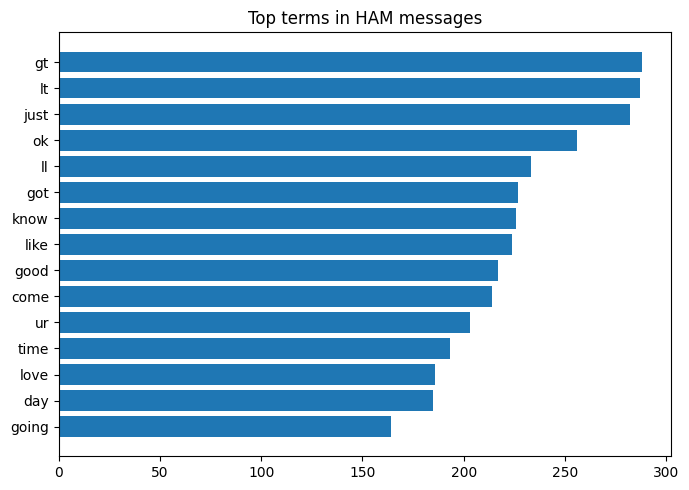

Top terms : SPAM


,term,frequency
0,free,190
1,txt,131
2,ur,119
3,stop,110
4,text,107
5,mobile,105
6,reply,96
7,claim,94
8,urltoken,88
9,prize,78


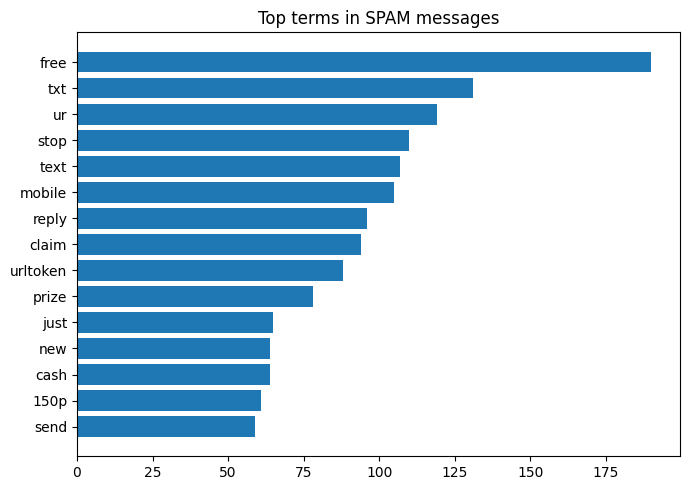

In [7]:
# Count words on the full de-duplicated corpus for descriptive analysis only.
eda_vectorizer = CountVectorizer(stop_words="english", max_features=5000)
word_counts = eda_vectorizer.fit_transform(df["cleaned_message"])
terms = np.array(eda_vectorizer.get_feature_names_out())

for class_name, class_value in [("ham", 0), ("spam", 1)]:
    class_mask = df["label"].to_numpy() == class_value
    frequencies = np.asarray(word_counts[class_mask].sum(axis=0)).ravel()

    # Select the 15 most frequent terms for this class.
    top_indices = np.argsort(frequencies)[-15:][::-1]
    top_terms = pd.DataFrame({
        "term": terms[top_indices],
        "frequency": frequencies[top_indices],
    })

    print(f"Top terms : {class_name.upper()}")
    display(top_terms)

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.barh(top_terms["term"][::-1], top_terms["frequency"][::-1])
    ax.set_title(f"Top terms in {class_name.upper()} messages")
    fig.tight_layout()
    fig.savefig(ASSET_DIR / f"03_top_terms_{class_name}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 7. Split the data into train, validation and test sets

I use three separate subsets because they have different roles:

- **training set**: learn model parameters;
- **validation set**: make development choices, such as early stopping and the decision threshold;
- **test set**: measure final performance after those choices are fixed.

The split is stratified so that the proportion of spam remains similar in all three subsets.

This separation is important because the test set should represent unseen data, not data used to tune the model.


In [8]:
# First reserve 30% of the data for validation + test.
train_df, temporary_df = train_test_split(
    df[["cleaned_message", "label", "Message"]],
    test_size=0.30,
    stratify=df["label"],
    random_state=SEED,
)

# Split the reserved 30% equally: 15% validation, 15% test.
validation_df, test_df = train_test_split(
    temporary_df,
    test_size=0.50,
    stratify=temporary_df["label"],
    random_state=SEED,
)

split_summary = pd.DataFrame(
    {
        "rows": [len(train_df), len(validation_df), len(test_df)],
        "ham": [
            int((train_df.label == 0).sum()),
            int((validation_df.label == 0).sum()),
            int((test_df.label == 0).sum()),
        ],
        "spam": [
            int((train_df.label == 1).sum()),
            int((validation_df.label == 1).sum()),
            int((test_df.label == 1).sum()),
        ],
    },
    index=["train", "validation", "test"],
)

display(split_summary)

,rows,ham,spam
train,3609,3160,449
validation,774,678,96
test,774,678,96


## 8. Convert training text into sequences for the BiLSTM

The BiLSTM cannot read raw text directly.

A tokenizer learns a vocabulary from the **training messages only** and converts words into integer IDs. Words that were not seen during training are mapped to an out-of-vocabulary token.

Messages are then padded to a common length. Instead of using the longest message in the corpus, I use the **95th percentile of training sequence lengths**. This keeps most messages intact without making every sequence unnecessarily long because of a few extreme cases.


In [9]:
MAX_VOCAB_SIZE = 5000
PAD_ID = 0
OOV_ID = 1

# Count words only in training messages.
word_counter = Counter()
for text in train_df["cleaned_message"]:
    word_counter.update(text.split())

# Reserve 0 for padding and 1 for unknown words.
word_index = {"<PAD>": PAD_ID, "<OOV>": OOV_ID}
for word, _ in word_counter.most_common(MAX_VOCAB_SIZE - 2):
    word_index[word] = len(word_index)


def texts_to_sequences(texts):
    """Convert cleaned messages into lists of integer word IDs."""
    return [
        [word_index.get(token, OOV_ID) for token in text.split()]
        for text in texts
    ]


# Convert each data split with the same training vocabulary.
train_sequences = texts_to_sequences(train_df["cleaned_message"])
validation_sequences = texts_to_sequences(validation_df["cleaned_message"])
test_sequences = texts_to_sequences(test_df["cleaned_message"])

# Choose sequence length from training data only.
train_lengths = np.array([len(sequence) for sequence in train_sequences])
MAX_SEQUENCE_LENGTH = max(10, int(np.percentile(train_lengths, 95)))

# Pad shorter messages and truncate longer messages.
X_train = keras.utils.pad_sequences(
    train_sequences,
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post",
)
X_validation = keras.utils.pad_sequences(
    validation_sequences,
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post",
)
X_test = keras.utils.pad_sequences(
    test_sequences,
    maxlen=MAX_SEQUENCE_LENGTH,
    padding="post",
    truncating="post",
)

y_train = train_df["label"].to_numpy()
y_validation = validation_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

print("Vocabulary size used:", len(word_index))
print("95th-percentile training sequence length:", MAX_SEQUENCE_LENGTH)
print("Maximum training sequence length:", int(train_lengths.max()))

Vocabulary size used: 5000
95th-percentile training sequence length: 33
Maximum training sequence length: 190


## 9. Account for class imbalance

Spam is much less frequent than ham.

During BiLSTM training, I use balanced class weights so that mistakes on spam messages carry more weight than they would in a purely frequency-based loss.

The weights are calculated from the training labels only.


In [10]:
classes = np.array([0, 1])
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train,
)

class_weight_dict = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, class_weights)
}

class_weight_dict

{0: 0.5710443037974684, 1: 4.018930957683741}

## 10. Build the BiLSTM

The neural network follows this structure:

`Embedding → Bidirectional LSTM → Dropout → Dense → Dropout → Sigmoid`

### Why this architecture?

- **Embedding** learns a numeric representation of words.
- **Bidirectional LSTM** reads the sequence in both directions and can use surrounding context.
- **Dropout** reduces overfitting.
- **Dense layers** combine the learned sequence representation.
- **Sigmoid output** returns a probability that the SMS is spam.

The model keeps the core idea of the original academic project while making the full experiment easier to compare with a simpler baseline.


In [11]:
EMBEDDING_DIM = 100

bilstm = keras.Sequential(
    [
        # Turn each word ID into a learned dense vector.
        layers.Embedding(
            input_dim=MAX_VOCAB_SIZE,
            output_dim=EMBEDDING_DIM,
            mask_zero=True,
        ),

        # Read the sequence in both directions.
        layers.Bidirectional(layers.LSTM(128, return_sequences=False)),

        # Dropout reduces overfitting by randomly disabling units during training.
        layers.Dropout(0.5),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),

        # One sigmoid output = estimated probability of spam.
        layers.Dense(1, activation="sigmoid"),
    ],
    name="sms_spam_bilstm",
)

bilstm.compile(
    loss="binary_crossentropy",
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    metrics=["accuracy"],
)

bilstm.summary()

Model: "sms_spam_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 11. Train the BiLSTM

The model is trained on the training set and monitored on the validation set.

I use **early stopping** on validation loss. Training stops when the model is no longer improving, and the best weights are restored.

This avoids choosing the number of epochs by looking at test performance.


In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    min_delta=1e-4,
)

history = bilstm.fit(
    X_train,
    y_train,
    validation_data=(X_validation, y_validation),
    epochs=20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping],
    verbose=2,
)

print("Epochs run:", len(history.history["loss"]))

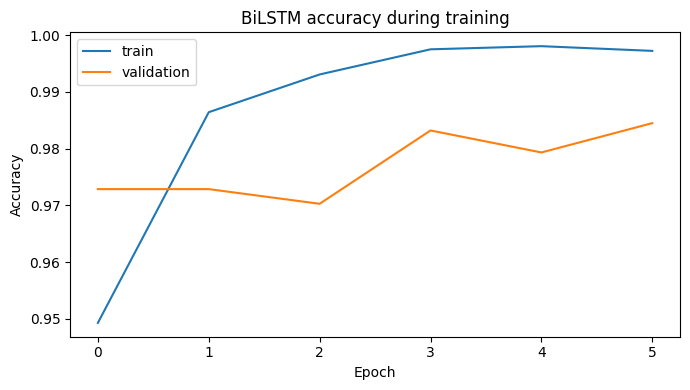

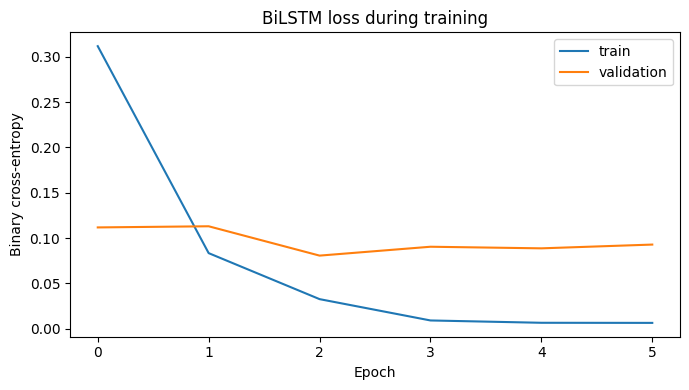

In [13]:
# Plot training and validation accuracy.
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history.history["accuracy"], label="train")
ax.plot(history.history["val_accuracy"], label="validation")
ax.set_title("BiLSTM accuracy during training")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.legend()
fig.tight_layout()
fig.savefig(ASSET_DIR / "04_bilstm_training_accuracy.png", dpi=160, bbox_inches="tight")
plt.show()

# Plot training and validation loss.
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(history.history["loss"], label="train")
ax.plot(history.history["val_loss"], label="validation")
ax.set_title("BiLSTM loss during training")
ax.set_xlabel("Epoch")
ax.set_ylabel("Binary cross-entropy")
ax.legend()
fig.tight_layout()
fig.savefig(ASSET_DIR / "05_bilstm_training_loss.png", dpi=160, bbox_inches="tight")
plt.show()

## 12. Choose the decision threshold

The BiLSTM returns a spam probability, not a final label.

A threshold is therefore needed:

- probability above the threshold → spam;
- probability below the threshold → ham.

Rather than fixing `0.50` automatically, I choose the threshold that gives the best **spam F1-score on the validation set**. The test set is not used for this decision.


In [14]:
def spam_metrics_at_threshold(y_true, probabilities, threshold):
    """Return precision, recall and F1 for the spam class at one threshold."""
    predictions = (probabilities >= threshold).astype(int)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        predictions,
        labels=[1],
        average=None,
        zero_division=0,
    )

    return float(precision[0]), float(recall[0]), float(f1[0])


validation_prob_bilstm = np.asarray(
    bilstm.predict(X_validation, verbose=0)
).ravel()

threshold_grid = np.arange(0.10, 0.91, 0.01)
threshold_results = []

for threshold in threshold_grid:
    precision, recall, f1 = spam_metrics_at_threshold(
        y_validation,
        validation_prob_bilstm,
        threshold,
    )
    threshold_results.append((threshold, precision, recall, f1))

bilstm_thresholds = pd.DataFrame(
    threshold_results,
    columns=["threshold", "spam_precision", "spam_recall", "spam_f1"],
)

# First maximize F1. Recall and precision are used only as tie-breakers.
best_bilstm_row = bilstm_thresholds.sort_values(
    ["spam_f1", "spam_recall", "spam_precision"],
    ascending=False,
).iloc[0]

BILSTM_THRESHOLD = float(best_bilstm_row["threshold"])

print(best_bilstm_row.round(4).to_string())
print("Frozen BiLSTM threshold:", round(BILSTM_THRESHOLD, 2))

threshold         0.8300
spam_precision    0.9775
spam_recall       0.9062
spam_f1           0.9405
Frozen BiLSTM threshold: 0.83


## 13. Evaluate the BiLSTM on unseen test messages

The final BiLSTM is evaluated on **774 test messages** that were not used to train the model or choose the threshold.

I report several metrics because accuracy alone can hide poor performance on the minority class:

- **accuracy**: overall proportion of correct predictions;
- **spam precision**: how often a message predicted as spam is actually spam;
- **spam recall**: how much of the real spam is detected;
- **spam F1-score**: balance between spam precision and recall;
- **ROC-AUC / PR-AUC**: ranking quality across possible thresholds.


accuracy          0.9832
spam_precision    0.9560
spam_recall       0.9062
spam_f1           0.9305
roc_auc           0.9937
pr_auc            0.9733
threshold         0.8300

Classification report:

              precision    recall  f1-score   support

         ham     0.9868    0.9941    0.9904       678
        spam     0.9560    0.9062    0.9305        96

    accuracy                         0.9832       774
   macro avg     0.9714    0.9502    0.9605       774
weighted avg     0.9830    0.9832    0.9830       774



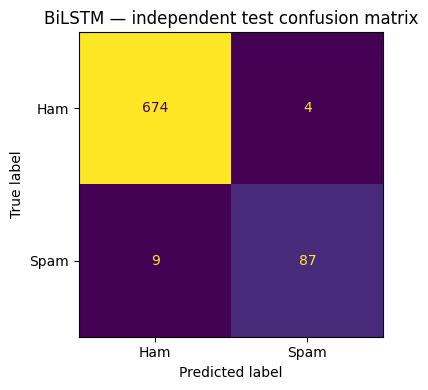

In [15]:
# Predict spam probabilities for the independent test set.
test_prob_bilstm = np.asarray(bilstm.predict(X_test, verbose=0)).ravel()

# Convert probabilities to class labels with the frozen validation-selected threshold.
bilstm_predictions = (test_prob_bilstm >= BILSTM_THRESHOLD).astype(int)

b_precision, b_recall, b_f1 = spam_metrics_at_threshold(
    y_test,
    test_prob_bilstm,
    BILSTM_THRESHOLD,
)

bilstm_metrics = {
    "accuracy": accuracy_score(y_test, bilstm_predictions),
    "spam_precision": b_precision,
    "spam_recall": b_recall,
    "spam_f1": b_f1,
    "roc_auc": roc_auc_score(y_test, test_prob_bilstm),
    "pr_auc": average_precision_score(y_test, test_prob_bilstm),
    "threshold": BILSTM_THRESHOLD,
}

print(pd.Series(bilstm_metrics).round(4).to_string())
print()
print("Classification report:")
print()
print(
    classification_report(
        y_test,
        bilstm_predictions,
        target_names=["ham", "spam"],
        digits=4,
        zero_division=0,
    )
)

bilstm_cm = confusion_matrix(y_test, bilstm_predictions)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    bilstm_cm,
    display_labels=["Ham", "Spam"],
).plot(ax=ax, colorbar=False)
ax.set_title("BiLSTM : independent test confusion matrix")
fig.tight_layout()
fig.savefig(ASSET_DIR / "06_bilstm_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

## 14. Build a simpler baseline: TF-IDF + Logistic Regression

A neural network is not automatically the best choice for a text-classification problem.

To test whether the BiLSTM adds real value, I compare it with a classical NLP pipeline:

1. **TF-IDF** converts words and n-grams into weighted numeric features;
2. **Logistic Regression** learns the decision boundary.

The TF-IDF vocabulary is learned from the training set only. Its final probability threshold is also selected on the validation set.

This gives the BiLSTM a meaningful baseline rather than comparing it only with itself.


In [16]:
# TF-IDF learns its vocabulary and statistics from the training text only.
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
)

X_train_tfidf = tfidf.fit_transform(train_df["cleaned_message"])
X_validation_tfidf = tfidf.transform(validation_df["cleaned_message"])
X_test_tfidf = tfidf.transform(test_df["cleaned_message"])

# Balanced class weights help the model pay more attention to minority spam examples.
baseline = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=SEED,
)
baseline.fit(X_train_tfidf, y_train)

# Select the baseline threshold on validation data exactly as we did for the BiLSTM.
validation_prob_baseline = baseline.predict_proba(X_validation_tfidf)[:, 1]
baseline_threshold_results = []

for threshold in threshold_grid:
    precision, recall, f1 = spam_metrics_at_threshold(
        y_validation,
        validation_prob_baseline,
        threshold,
    )
    baseline_threshold_results.append((threshold, precision, recall, f1))

baseline_thresholds = pd.DataFrame(
    baseline_threshold_results,
    columns=["threshold", "spam_precision", "spam_recall", "spam_f1"],
)

best_baseline_row = baseline_thresholds.sort_values(
    ["spam_f1", "spam_recall", "spam_precision"],
    ascending=False,
).iloc[0]

BASELINE_THRESHOLD = float(best_baseline_row["threshold"])

print(best_baseline_row.round(4).to_string())
print("Frozen baseline threshold:", round(BASELINE_THRESHOLD, 2))

threshold         0.5600
spam_precision    0.9341
spam_recall       0.8854
spam_f1           0.9091
Frozen baseline threshold: 0.56


accuracy          0.9793
spam_precision    0.9348
spam_recall       0.8958
spam_f1           0.9149
roc_auc           0.9953
pr_auc            0.9749
threshold         0.5600

Classification report:

              precision    recall  f1-score   support

         ham     0.9853    0.9912    0.9882       678
        spam     0.9348    0.8958    0.9149        96

    accuracy                         0.9793       774
   macro avg     0.9601    0.9435    0.9516       774
weighted avg     0.9791    0.9793    0.9791       774



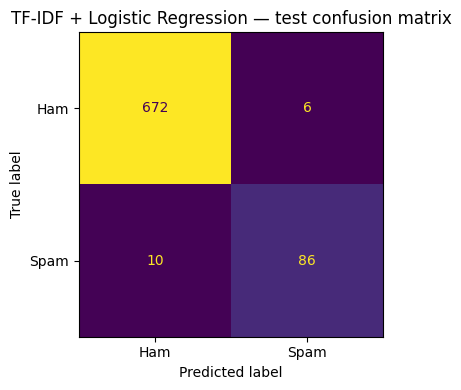

In [17]:
# Final baseline evaluation on the same untouched test set.
test_prob_baseline = baseline.predict_proba(X_test_tfidf)[:, 1]
baseline_predictions = (test_prob_baseline >= BASELINE_THRESHOLD).astype(int)

l_precision, l_recall, l_f1 = spam_metrics_at_threshold(
    y_test,
    test_prob_baseline,
    BASELINE_THRESHOLD,
)

baseline_metrics = {
    "accuracy": accuracy_score(y_test, baseline_predictions),
    "spam_precision": l_precision,
    "spam_recall": l_recall,
    "spam_f1": l_f1,
    "roc_auc": roc_auc_score(y_test, test_prob_baseline),
    "pr_auc": average_precision_score(y_test, test_prob_baseline),
    "threshold": BASELINE_THRESHOLD,
}

print(pd.Series(baseline_metrics).round(4).to_string())
print()
print("Classification report:")
print()
print(
    classification_report(
        y_test,
        baseline_predictions,
        target_names=["ham", "spam"],
        digits=4,
        zero_division=0,
    )
)

baseline_cm = confusion_matrix(y_test, baseline_predictions)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    baseline_cm,
    display_labels=["Ham", "Spam"],
).plot(ax=ax, colorbar=False)
ax.set_title("TF-IDF + Logistic Regression : test confusion matrix")
fig.tight_layout()
fig.savefig(ASSET_DIR / "07_baseline_confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

## 15. Compare both approaches

The comparison focuses on the spam class because spam is the minority class and the main target of the project.

The BiLSTM performs slightly better on the final thresholded classification metrics, while the TF-IDF baseline remains very close and even records slightly stronger ROC-AUC / PR-AUC.

That makes the result more useful than a simple “deep learning wins” conclusion: the extra complexity produces only a modest gain on this dataset.


,accuracy,spam_precision,spam_recall,spam_f1,roc_auc,pr_auc,threshold
BiLSTM,0.9832,0.9560,0.9062,0.9305,0.9937,0.9733,0.83
TF-IDF + Logistic Regression,0.9793,0.9348,0.8958,0.9149,0.9953,0.9749,0.56


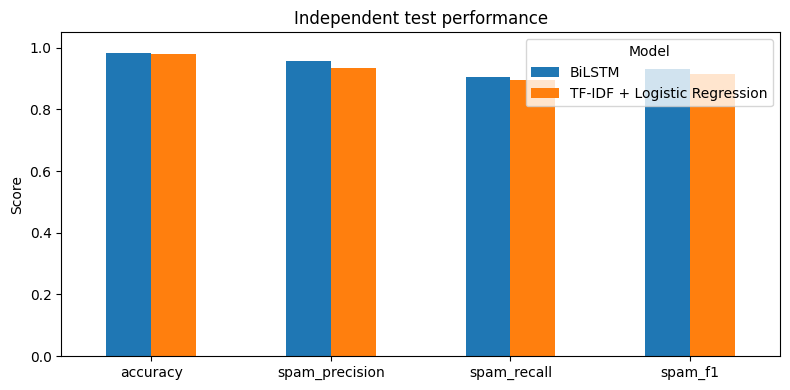

In [18]:
comparison = pd.DataFrame(
    [bilstm_metrics, baseline_metrics],
    index=["BiLSTM", "TF-IDF + Logistic Regression"],
)

display(comparison.round(4))

# Visual comparison of the most intuitive classification metrics.
plot_metrics = comparison[[
    "accuracy",
    "spam_precision",
    "spam_recall",
    "spam_f1",
]].T

ax = plot_metrics.plot(kind="bar", figsize=(8, 4))
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Independent test performance")
ax.legend(title="Model")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(ASSET_DIR / "08_model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## 16. Inspect the remaining errors

A confusion matrix tells us how many errors were made, but not what those messages look like.

I inspect:

- **false negatives**: spam that the model allowed through;
- **false positives**: legitimate messages incorrectly blocked as spam.

This helps identify ambiguous language, unusual wording and cases where future features or more training data could improve the system.


In [19]:
def redact_for_display(text):
    """Hide URLs and long number sequences in displayed error examples."""
    text = URL_PATTERN.sub("[URL]", str(text))
    text = re.sub(r"\b\d{3,}\b", "[NUMBER]", text)
    return text[:220] + ("…" if len(text) > 220 else "")


errors = test_df[["Message", "label"]].copy()
errors["bilstm_pred"] = bilstm_predictions
errors["baseline_pred"] = baseline_predictions
errors["display_message"] = errors["Message"].map(redact_for_display)

print("BiLSTM false negatives : real spam classified as ham:")
display(
    errors[(errors.label == 1) & (errors.bilstm_pred == 0)][["display_message"]].head(5)
)

print("BiLSTM false positives : real ham classified as spam:")
display(
    errors[(errors.label == 0) & (errors.bilstm_pred == 1)][["display_message"]].head(5)
)

print("Baseline false negatives:")
display(
    errors[(errors.label == 1) & (errors.baseline_pred == 0)][["display_message"]].head(5)
)

print("Baseline false positives:")
display(
    errors[(errors.label == 0) & (errors.baseline_pred == 1)][["display_message"]].head(5)
)

BiLSTM false negatives : real spam classified as ham:


,display_message
671,Hi I'm sue. I am 20 years old and work as a la...
2637,Burger King - Wanna play footy at a top stadiu...
3943,Missed call alert. These numbers called but le...
5125,Want explicit SEX in 30 secs? Ring [NUMBER] no...
5050,"Latest News! Police station toilet stolen, cop..."


BiLSTM false positives : real ham classified as spam:


,display_message
3258,Nowadays people are notixiquating the laxinorf...
4283,I wanted to wish you a Happy New Year and I wa...
4409,I (Career Tel) have added u as a contact on IN...
3593,Please protect yourself from e-threats. SIB ne...


Baseline false negatives:


,display_message
671,Hi I'm sue. I am 20 years old and work as a la...
2637,Burger King - Wanna play footy at a top stadiu...
3943,Missed call alert. These numbers called but le...
5125,Want explicit SEX in 30 secs? Ring [NUMBER] no...
5050,"Latest News! Police station toilet stolen, cop..."


Baseline false positives:


,display_message
152,Ok... Ur typical reply...
178,Hi! You just spoke to MANEESHA V. We'd like to...
3331,I'm at home. Please call
4409,I (Career Tel) have added u as a contact on IN...
3593,Please protect yourself from e-threats. SIB ne...


## 17. Test the models on new messages

This helper function shows how the two trained models classify a new SMS.

It is included to demonstrate the inference flow from raw text to final prediction. It is not presented as a production messaging service.


In [20]:
def predict_message(message):
    """Return predictions from both final models for one new SMS."""
    cleaned = clean_text(message)

    # ----- BiLSTM path -----
    sequence = texts_to_sequences(pd.Series([cleaned]))
    padded = keras.utils.pad_sequences(
        sequence,
        maxlen=MAX_SEQUENCE_LENGTH,
        padding="post",
        truncating="post",
    )
    bilstm_probability = float(
        np.asarray(bilstm.predict(padded, verbose=0)).ravel()[0]
    )

    # ----- TF-IDF + Logistic Regression path -----
    baseline_probability = float(
        baseline.predict_proba(tfidf.transform([cleaned]))[0, 1]
    )

    return {
        "BiLSTM": {
            "label": "SPAM" if bilstm_probability >= BILSTM_THRESHOLD else "HAM",
            "spam_probability": round(bilstm_probability, 4),
            "threshold": round(BILSTM_THRESHOLD, 2),
        },
        "TF-IDF + Logistic Regression": {
            "label": "SPAM" if baseline_probability >= BASELINE_THRESHOLD else "HAM",
            "spam_probability": round(baseline_probability, 4),
            "threshold": round(BASELINE_THRESHOLD, 2),
        },
    }


print(predict_message("Congratulations! You've won a free prize. Click here now."))
print(predict_message("Can we meet at the library at 5?"))

{'BiLSTM': {'label': 'SPAM', 'spam_probability': 0.9502, 'threshold': 0.83}, 'TF-IDF + Logistic Regression': {'label': 'SPAM', 'spam_probability': 0.776, 'threshold': 0.56}}
{'BiLSTM': {'label': 'HAM', 'spam_probability': 0.0012, 'threshold': 0.83}, 'TF-IDF + Logistic Regression': {'label': 'HAM', 'spam_probability': 0.0704, 'threshold': 0.56}}


## Results, limits and what I learned

The BiLSTM achieved the best spam F1-score on the independent test set:

- **98.32% accuracy**
- **95.60% spam precision**
- **90.62% spam recall**
- **0.930 spam F1**

TF-IDF + Logistic Regression stayed close at **0.915 spam F1**.

That comparison was the most useful part of the project for me. The BiLSTM performed better, but the gain was not large. In a real system I would therefore compare model quality with inference cost, latency and maintenance before choosing the final solution.

Main limits:
- relatively small and old SMS corpus;
- no multilingual evaluation;
- no external test dataset;
- no production latency or drift monitoring.

A next version could test newer external data, character-level or Transformer models, and an API with measured inference latency.


## Resources

- Source dataset: `spam.csv`
- Main technologies: Python, pandas, scikit-learn, Keras, TF-IDF, Logistic Regression, BiLSTM
- Final notebook purpose: reproducible academic case study and portfolio evidence

This public notebook documents the project workflow and the evaluation used in the portfolio case study.


## 19. Save the key results

The final cell exports the main metrics and settings in JSON format. This makes it easier to keep documentation and reported results consistent with the executed notebook.


In [21]:
run_metadata = {
    "seed": SEED,
    "keras_version": keras.__version__,
    "keras_backend": keras.backend.backend(),
    "raw_rows": len(df_raw),
    "raw_ham": int((df_raw.Category == "ham").sum()),
    "raw_spam": int((df_raw.Category == "spam").sum()),
    "exact_duplicates_removed": exact_duplicates,
    "unique_rows": len(df),
    "unique_ham": int((df.Category == "ham").sum()),
    "unique_spam": int((df.Category == "spam").sum()),
    "train_rows": len(train_df),
    "validation_rows": len(validation_df),
    "test_rows": len(test_df),
    "vocabulary_size": len(word_index),
    "max_sequence_length": MAX_SEQUENCE_LENGTH,
    "bilstm": {key: float(value) for key, value in bilstm_metrics.items()},
    "baseline": {key: float(value) for key, value in baseline_metrics.items()},
    "bilstm_confusion_matrix": bilstm_cm.tolist(),
    "baseline_confusion_matrix": baseline_cm.tolist(),
}

with open(ASSET_DIR / "run_metadata.json", "w", encoding="utf-8") as file:
    json.dump(run_metadata, file, indent=2)

comparison.to_csv(ASSET_DIR / "model_comparison.csv")
bilstm_thresholds.to_csv(
    ASSET_DIR / "bilstm_validation_thresholds.csv",
    index=False,
)
baseline_thresholds.to_csv(
    ASSET_DIR / "baseline_validation_thresholds.csv",
    index=False,
)

winner = comparison["spam_f1"].idxmax()
print(
    f"Canonical conclusion: on the independent {len(test_df)}-message test set, "
    f"{winner} achieved the higher spam F1 score."
)
print()
print("Final comparison:")
display(comparison.round(4))

Canonical conclusion: on the independent 774-message test set, BiLSTM achieved the higher spam F1 score.

Final comparison:


,accuracy,spam_precision,spam_recall,spam_f1,roc_auc,pr_auc,threshold
BiLSTM,0.9832,0.9560,0.9062,0.9305,0.9937,0.9733,0.83
TF-IDF + Logistic Regression,0.9793,0.9348,0.8958,0.9149,0.9953,0.9749,0.56
